# 02 — Building a target and shooting rays through it

*Weeks 3–4*

In this notebook you build the virtual target and implement the first student-owned analysis function. The ray-marching physics is supplied in `muography.py`; your job is to assemble it into an opacity map.


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../code'))
import numpy as np
import matplotlib.pyplot as plt
import muography as mg
import project_config as cfg
import student_analysis as sa
print('ready')


ready


## The target

`mg.Pyramid` is a square-based pyramid with a 230 m base and 139 m height. The baseline chamber is a **10 m radius (20 m diameter)** sphere centred at `(0, 0, 70)`. These values are stored in `project_config.py` so that all notebooks use the same baseline.


In [2]:
target = mg.Pyramid(
    base=cfg.PYRAMID_BASE_M, height=cfg.PYRAMID_HEIGHT_M,
    density=cfg.ROCK_DENSITY_G_CM3, void_centre=cfg.VOID_CENTRE_M,
    void_radius=cfg.VOID_RADIUS_M, has_void=True,
)
print('inside the void  :', target.density_at(0, 0, 70), 'g/cm^3')
print('inside the rock  :', target.density_at(0, 0, 30), 'g/cm^3')
print('outside entirely :', target.density_at(200, 0, 10), 'g/cm^3')


inside the void  : 0.0012 g/cm^3
inside the rock  : 2.5 g/cm^3
outside entirely : 0.0012 g/cm^3


### YOUR TURN — look at what you have built

Make a vertical slice through the middle of the pyramid and show the chamber. Label the axes in metres and the colourbar in `g/cm³`.


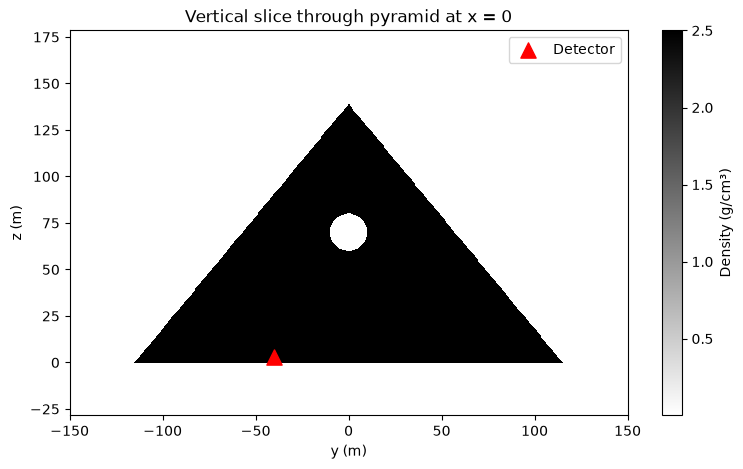

In [3]:
y = np.linspace(-130, 130, 500)
z = np.linspace(0, 150, 500)
# grid
Y, Z = np.meshgrid(y, z)
# middle vertical slice
X = np.zeros_like(Y)

p = target.density_at(X, Y, Z)

plt.figure(figsize=(9, 5))

# Darker = more density
plt.pcolormesh(
    Y, Z, p,
    shading="auto",
    cmap="gray_r"
)
plt.colorbar(label="Density (g/cm³)")

detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)
plt.scatter(
    detector[1],
    detector[2],
    marker="^",
    s=120,
    color="red",
    label="Detector",
)
plt.legend()


plt.xlabel("y (m)")
plt.ylabel("z (m)")

plt.title("Vertical slice through pyramid at x = 0")

plt.axis("equal")
plt.xlim(-150, 150)
plt.xticks(np.arange(-150, 151, 50))

plt.show()

## Where does the detector go?

The baseline detector position is `(0, -40, 3)` m. The direction functions use two pointing angles, `ax` and `ay`; together they define the viewing direction.


In [4]:
detector = np.array(cfg.DETECTOR_POSITION_M, dtype=float)
d = mg.direction_from_angles(0.0, 0.0)
print('straight up:', d, '-> zenith', np.degrees(mg.zenith_from_direction(d)), 'deg')


straight up: [0. 0. 1.] -> zenith 0.0 deg


## Ray marching — supplied physics

`mg.trace_one_ray` is the supplied single-ray function. Read it before using it. It walks along a ray in 0.25 m steps and accumulates density × path length.


In [5]:
for deg in [0, 10, 20, 25, 30, 35, 40]:
    d = mg.direction_from_angles(0.0, np.radians(deg))
    X = mg.trace_one_ray(target, detector, d, step=cfg.RAY_STEP_M)
    print(f'ay = {deg:3d} deg   opacity = {X:9.0f} g/cm^2   ({X/100/2.5:6.1f} m of limestone)')


ay =   0 deg   opacity =     21999 g/cm^2   (  88.0 m of limestone)
ay =  10 deg   opacity =     28371 g/cm^2   ( 113.5 m of limestone)
ay =  20 deg   opacity =     34118 g/cm^2   ( 136.5 m of limestone)
ay =  25 deg   opacity =     29620 g/cm^2   ( 118.5 m of limestone)
ay =  30 deg   opacity =     26497 g/cm^2   ( 106.0 m of limestone)
ay =  35 deg   opacity =     26434 g/cm^2   ( 105.7 m of limestone)
ay =  40 deg   opacity =     29933 g/cm^2   ( 119.7 m of limestone)


### YOUR TURN — find the void by hand

Scan `ay` from 15° to 45° in 1° steps. Plot the opacity for the target and for `target.without_void()`. The chamber should create a notch that is absent in the no-void control.


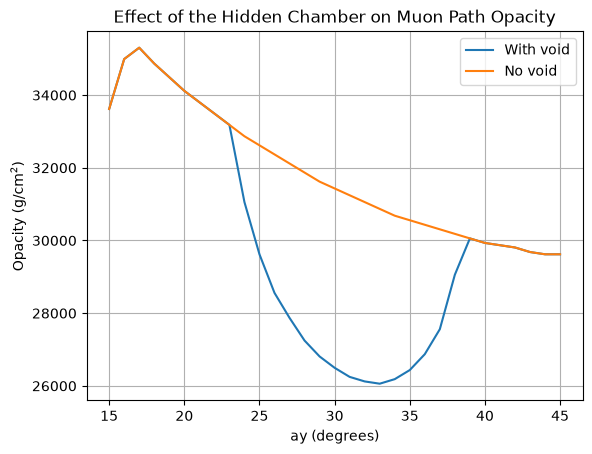

In [6]:
angles = np.arange(15, 46, 1)
opacity_void = []
opacity_no_void = []
solid_target = target.without_void()

# same ray for both pyramids, so the notch comes from the chamber
for ay in angles:
    direction = mg.direction_from_angles(0.0, np.radians(ay))
    opacity_void.append(mg.trace_one_ray(target, detector, direction, step=cfg.RAY_STEP_M))
    opacity_no_void.append(mg.trace_one_ray(solid_target, detector, direction, step=cfg.RAY_STEP_M))

plt.plot(angles, opacity_void, label="With void")
plt.plot(angles, opacity_no_void, label="No void")
plt.xlabel("ay (degrees)")
plt.ylabel(r"Opacity (g/cm$^2$)")
plt.title("Effect of the Hidden Chamber on Muon Path Opacity")
plt.legend()
plt.grid()
plt.show()

tan^-1 (40/67) = 30.8 degrees

## Making a whole image

### YOUR TURN — implement the shared function

Open `code/student_analysis.py` and implement:

```python
opacity_map(target, detector, field_deg=40, step_deg=2)
```

It should build `ax` and `ay` grids, trace one ray per direction using `mg.direction_from_angles` and `mg.trace_one_ray`, and return `(opacity, ax_deg, ay_deg)`. Keep the angle grids in degrees for plotting.

**Important:** this function lives in `student_analysis.py`, not only in this notebook. That makes notebooks 03–05 reproducible from a fresh kernel.


In [7]:
# After implementing the function in code/student_analysis.py, run this cell.
opacity, ax_deg, ay_deg = sa.opacity_map(target, detector)
print('shape:', opacity.shape)
# set the edges half a bin beyond the centres so each square lines up
half_bin = cfg.STEP_DEG / 2
extent = [ax_deg.min() - half_bin, ax_deg.max() + half_bin,
          ay_deg.min() - half_bin, ay_deg.max() + half_bin]

shape: (41, 41)


### YOUR TURN — display and validate

Display the opacity map with `origin='lower'`. Then repeat it for `target.without_void()`. Finally, repeat the map with `ray_step=0.125` m and compare it with the 0.25 m result. The change should be small.


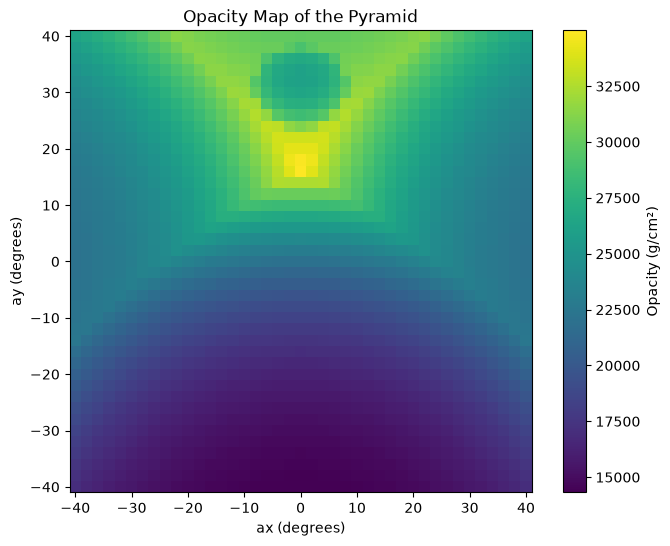

In [8]:
plt.figure(figsize=(8, 6))

plt.imshow(
    opacity,
    origin="lower",
    extent=extent,
    cmap="viridis"
)

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Opacity Map of the Pyramid")

plt.colorbar(label="Opacity (g/cm²)")

plt.show()

In [9]:
opacity_fine, ax_fine, ay_fine = sa.opacity_map(target,detector,ray_step=0.125)

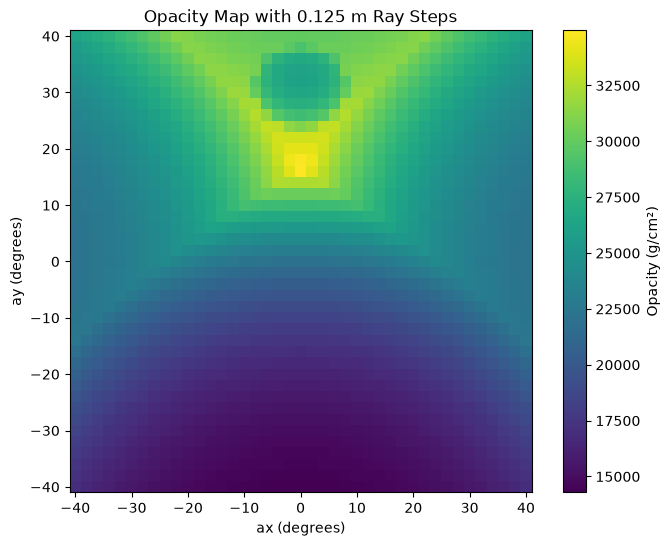

In [10]:
plt.figure(figsize=(8, 6))

plt.imshow(
    opacity_fine,
    origin="lower",
    extent=extent,
    cmap="viridis"
)

plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Opacity Map with 0.125 m Ray Steps")

plt.colorbar(label="Opacity (g/cm²)")
plt.show()

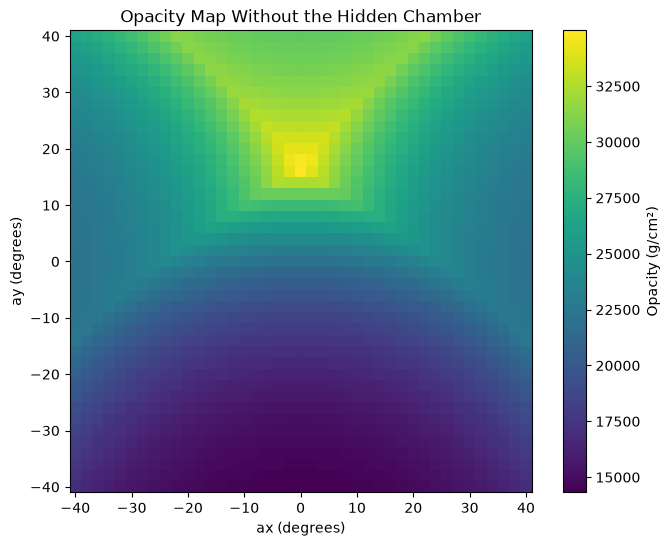

In [11]:
# use the same solid twin as in the one-ray check
opacity_solid, ax_solid, ay_solid = sa.opacity_map(solid_target,detector)
plt.figure(figsize=(8, 6))

plt.imshow(opacity_solid,origin="lower",extent=extent, cmap="viridis")
plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Opacity Map Without the Hidden Chamber")

plt.colorbar(label="Opacity (g/cm²)")
plt.show()

In [12]:
# same rock model, just twice as many samples along each ray
difference = np.abs(opacity_fine - opacity)
max_diff = difference.max()
mean_diff = difference.mean()
percent_change = 100 * difference / np.maximum(opacity, 1e-12)

print(f"Maximum difference: {max_diff:.1f} g/cm²")
print(f"Mean difference: {mean_diff:.1f} g/cm²")
print(f"Maximum per-pixel change: {percent_change.max():.2f}%")
print(f"Mean per-pixel change: {percent_change.mean():.2f}%")

Maximum difference: 62.5 g/cm²
Mean difference: 15.5 g/cm²
Maximum per-pixel change: 0.24%
Mean per-pixel change: 0.07%


The density at each point is the same - its just the sampling count thats different - so the percentage difference is very small

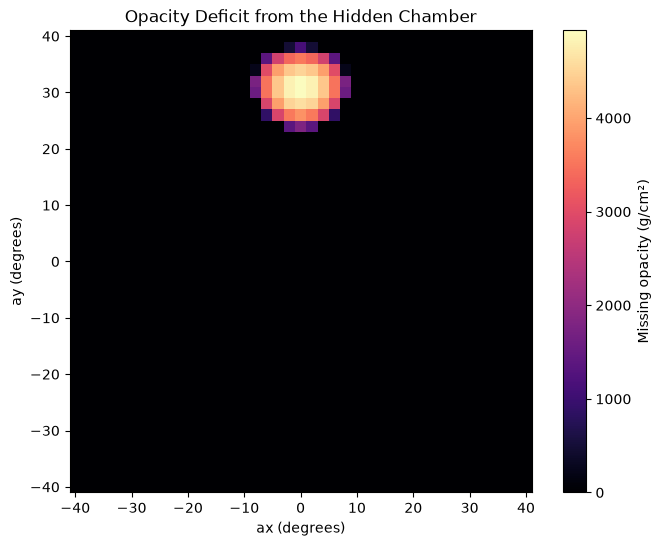

Largest deficit: 4935 g/cm²
Largest difference on rays that miss the chamber: 0.0 g/cm²


In [13]:
# take away the solid map so we can actually see where the rock is missing
opacity_deficit = opacity_solid - opacity
plt.figure(figsize=(8, 6))
plt.imshow(opacity_deficit, origin="lower", extent=extent, cmap="magma")
plt.colorbar(label="Missing opacity (g/cm²)")
plt.xlabel("ax (degrees)")
plt.ylabel("ay (degrees)")
plt.title("Opacity Deficit from the Hidden Chamber")
plt.show()
print(f"Largest deficit: {opacity_deficit.max():.0f} g/cm²")
# rays that miss the sphere should agree with the solid reference
directions = mg.direction_from_angles(np.radians(ax_deg), np.radians(ay_deg))
to_chamber = np.asarray(cfg.VOID_CENTRE_M) - detector
along_ray = directions @ to_chamber
misses_chamber = np.linalg.norm(to_chamber - along_ray[..., None] * directions, axis=-1) > cfg.VOID_RADIUS_M
print(f"Largest difference on rays that miss the chamber: {np.abs(opacity_deficit[misses_chamber]).max():.1f} g/cm²")